## Anomaly detection based on traffic intensity

**Task:** Can we detect when a trafic camera is at fault?

**Our approach:** 

1. Select three consecutive junctions along the same road. 
2. We account for an estimated 30-second travel time between neighboring junctions, then compare detections within 30-minute windows.
3. We used KS distance to measure the largest vertical gap between the detection-count ECDFs and Wasserstein distance to measure the area between them. We computed the score between the cameras: 

3. When one sensor differs substantially from both others while those two agree, we flag that window as a potential anomaly.

## Example Location
Bridge–Highschool, Bridge–Corbins, and Bridge–Frantz. At each junction, we chose the northwest-facing sensor, so all three observe traffic moving in the same direction.

We compare each camera with the other two using **KS distance between ECDFs** and **Wasserstein distance**. A window is flagged only when **both methods** detect a deviation for the same camera and their reference-agreement checks pass. Thresholds are exploratory, not calibrated probabilities. Rows include repeated request updates.

![image.png](map.png)

## Prepar data and cameras


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wasserstein_distance

DAY = "2026-10-15"
COUNT_MODE = "rows"  # Or "first_seen_requests" to remove repeated request updates.
BIN = "30s"
WINDOW = "30min"
TRAVEL_SECONDS = 30

# Editable candidate-flag thresholds (not calibrated against labeled faults).
KS_THRESHOLD = 0.15
REFERENCE_KS_MAX = 0.15
W1_THRESHOLD = 1.0  # Counts per 30-second bin.
REFERENCE_W1_MAX = 1.0

# Works when launched from the notebook folder or the mobility workspace.
DATA_FILE = next(
    (folder / f"{DAY}.parquet" for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / f"{DAY}.parquet").is_file()),
    None,
)
if DATA_FILE is None:
    raise FileNotFoundError(f"Set DATA_FILE to the location of {DAY}.parquet")

cameras = pd.DataFrame([
    ["s1", "bridge.highschool_13", "SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw", "23.13", TRAVEL_SECONDS],
    ["s2", "bridge.corbins_12", "SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw", "13.12", 0],
    ["s3", "bridge.frantz_9", "SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw", "12.9", -TRAVEL_SECONDS],
], columns=["camera", "intersection", "sensor_id", "incoming_link", "shift_seconds"])
display(cameras)
print("Reading:", DATA_FILE)

,camera,intersection,sensor_id,incoming_link,shift_seconds
0,s1,bridge.highschool_13,SENSOR-bridge.highschool_13-fc_du_bridge.highs...,23.13,30
1,s2,bridge.corbins_12,SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw,13.12,0
2,s3,bridge.frantz_9,SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw,12.9,-30


Reading: /home/michal/mobility/ai_hack_mobility_2026/2026-10-15.parquet


## Select data associated with specific cameras

Strip the changing object/counter suffix from `sourceId`, preserving the location and NW direction. Require both the camera's own intersection and the specified incoming link, so forwarded records at other junctions and other approaches do not inflate the comparison. `REMOTE_SENSOR`, `NTCIP_CALL`, and `STARVATION` records are excluded. The audit shows records removed by the approach filter.

In [3]:
raw = pd.read_parquet(
    DATA_FILE,
    columns=["timestamp", "intersection_id", "source", "sourceId", "incomingLink_id", "id"],
    filters=[("intersection_id", "in", cameras["intersection"].tolist()), ("source", "==", "SENSOR")],
)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw["sensor_id"] = raw["sourceId"].str.replace(
    r"^(SENSOR-.*_(?:ne|nw|se|sw|n|e|s|w))\d+.*$", r"\1", regex=True
)
start = pd.Timestamp(DAY)
end = start + pd.Timedelta(days=1)
raw = raw[(raw["timestamp"] >= start) & (raw["timestamp"] < end)]

streams = {}
audit_rows = []
if COUNT_MODE not in ["rows", "first_seen_requests"]:
    raise ValueError("COUNT_MODE must be rows or first_seen_requests")
for camera in cameras.itertuples(index=False):
    selected = raw[(raw["intersection_id"] == camera.intersection)
                   & (raw["sensor_id"] == camera.sensor_id)].copy()
    approach = selected[selected["incomingLink_id"] == camera.incoming_link].sort_values("timestamp")
    events = approach.copy()
    if COUNT_MODE == "first_seen_requests":
        events = events.dropna(subset=["id"]).drop_duplicates("id", keep="first")
    streams[camera.camera] = events
    audit_rows.append({
        "camera": camera.camera, "camera_rows": len(selected),
        "excluded_other_links": len(selected) - len(approach),
        "selected_rows": len(approach), "distinct_request_ids": approach["id"].nunique(),
        "missing_request_ids": approach["id"].isna().sum(),
        "counted_events": len(events), "first_record": approach["timestamp"].min(),
        "last_record": approach["timestamp"].max(),
    })
audit = pd.DataFrame(audit_rows).set_index("camera")
display(audit)
if (audit["counted_events"] == 0).any():
    print("Warning: at least one selected camera has no records; check selection and data availability.")

,camera_rows,excluded_other_links,selected_rows,distinct_request_ids,missing_request_ids,counted_events,first_record,last_record
camera,,,,,,,,
s1,22840,70,22770,17086,0,22770,2026-10-15 00:00:01.019,2026-10-15 23:59:59.307
s2,24437,175,24262,18524,0,24262,2026-10-15 00:00:11.706,2026-10-15 23:59:58.140
s3,31955,164,31791,19546,0,31791,2026-10-15 00:00:12.010,2026-10-15 23:59:59.675


## Align the count streams

For example, s1 at 12:00:00, s2 at 12:00:30, and s3 at 12:01:00 all align to 12:00:30. Empty bins inside the file's nominal day count as zero; without sensor heartbeat data, zero cannot distinguish no traffic from missing reporting. The first and last half-hours have 59 common bins; interior windows have 60.

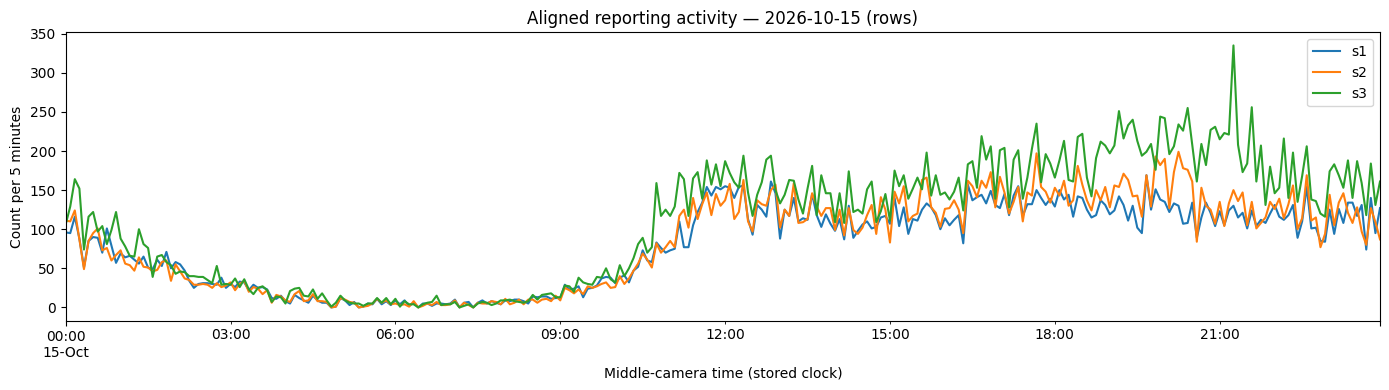

In [4]:
bin_width = pd.Timedelta(BIN)
grid = pd.date_range(start, end, freq=BIN, inclusive="left")
aligned = pd.DataFrame(index=grid)
for camera in cameras.itertuples(index=False):
    shift = pd.Timedelta(seconds=camera.shift_seconds)
    times = streams[camera.camera]["timestamp"] + shift
    counts = times.dt.floor(BIN).value_counts().reindex(grid, fill_value=0).sort_index()
    # A complete bin must fall within the shifted source day's coverage.
    available = (grid >= start + shift) & (grid + bin_width <= end + shift)
    aligned[camera.camera] = counts.astype(float).where(available)
aligned.index.name = "middle_camera_time"

aligned.resample("5min").sum(min_count=1).plot(figsize=(14, 4))
plt.title(f"Aligned reporting activity — {DAY} ({COUNT_MODE})")
plt.xlabel("Middle-camera time (stored clock)")
plt.ylabel("Count per 5 minutes")
plt.tight_layout()
plt.show()

## Combined ECDF and Wasserstein comparison

**KS** is the maximum vertical gap between ECDFs (0–1). **Wasserstein (W1)** is the area between them, measured in counts per bin.

For each method and camera i, with references j and k:
`score = max(0, min(distance(i,j), distance(i,k)) - distance(j,k))`.

Each method flags only if its score exceeds its threshold **and the other two cameras agree**. The final rule is **`anomaly = ks_flag AND w1_flag`**, for the same camera and half-hour. A single-method flag is retained for inspection but is not a final anomaly. Both methods use the same data and are not independent confirmations. They ignore ordering within a window; all-silent windows are reported separately.

In [5]:
def ks_distance(a, b):
    a, b = np.sort(np.asarray(a)), np.sort(np.asarray(b))
    if len(a) == 0 or len(b) == 0:
        return np.nan
    values = np.unique(np.concatenate([a, b]))
    fa = np.searchsorted(a, values, side="right") / len(a)
    fb = np.searchsorted(b, values, side="right") / len(b)
    return float(np.max(np.abs(fa - fb)))



def method_result(distances, sensor, threshold, reference_max):
    other = [s for s in sensors if s != sensor]
    d1 = distances[tuple(sorted([sensor, other[0]]))]
    d2 = distances[tuple(sorted([sensor, other[1]]))]
    reference = distances[tuple(sorted(other))]
    score = max(0.0, min(d1, d2) - reference)
    return score, reference, score >= threshold and reference <= reference_max


sensors = ["s1", "s2", "s3"]
pairs = [("s1", "s2"), ("s1", "s3"), ("s2", "s3")]
assert 0 < KS_THRESHOLD <= 1 and 0 <= REFERENCE_KS_MAX <= 1
assert np.isfinite(W1_THRESHOLD) and W1_THRESHOLD > 0
assert np.isfinite(REFERENCE_W1_MAX) and REFERENCE_W1_MAX >= 0
rows = []
for window_start in pd.date_range(start, end, freq=WINDOW, inclusive="left"):
    window_end = window_start + pd.Timedelta(WINDOW)
    common = aligned.loc[(aligned.index >= window_start) & (aligned.index < window_end)].dropna()
    ks = {pair: ks_distance(common[pair[0]], common[pair[1]]) for pair in pairs}
    w1 = {pair: wasserstein_distance(common[pair[0]], common[pair[1]])
          if len(common) else np.nan for pair in pairs}
    for sensor in sensors:
        ks_score, ks_reference, ks_flag = (method_result(ks, sensor, KS_THRESHOLD, REFERENCE_KS_MAX)
                                           if len(common) else (np.nan, np.nan, False))
        w1_score, w1_reference, w1_flag = (method_result(w1, sensor, W1_THRESHOLD, REFERENCE_W1_MAX)
                                           if len(common) else (np.nan, np.nan, False))
        rows.append({
            "window_start": window_start, "window_end": window_end, "sensor": sensor,
            "common_bins": len(common),
            "ks_score": ks_score, "ks_reference": ks_reference, "ks_flag": ks_flag,
            "w1_score": w1_score, "w1_reference": w1_reference, "w1_flag": w1_flag,
            "anomaly": bool(ks_flag and w1_flag),
            "status": "no_coverage" if common.empty else
                      "all_silent" if common.to_numpy().sum() == 0 else "evaluated",
        })
results = pd.DataFrame(rows)
# 48 windows, with both scores and the combined decision for each camera.
summary = results.pivot(index="window_start", columns="sensor", values=["ks_score", "w1_score", "anomaly"])
with pd.option_context("display.max_rows", 48):
    display(summary.round(3))
display(results.groupby("sensor")[["ks_flag", "w1_flag", "anomaly"]].sum())
assert results["anomaly"].equals(results["ks_flag"] & results["w1_flag"])


ks_score                      w1_score            \
sensor                     s1        s2        s3        s1        s2   
window_start                                                            
2026-10-15 00:00:00       0.0       0.0  0.084746       0.0       0.0   
2026-10-15 00:30:00       0.0       0.0  0.083333       0.0       0.0   
2026-10-15 01:00:00       0.0       0.0  0.066667       0.0       0.0   
2026-10-15 01:30:00       0.0  0.066667       0.0       0.0       0.2   
2026-10-15 02:00:00       0.0  0.016667       0.0       0.0       0.1   
2026-10-15 02:30:00       0.0       0.0       0.1       0.0       0.0   
2026-10-15 03:00:00  0.016667       0.0       0.0       0.0  0.033333   
2026-10-15 03:30:00       0.0       0.0       0.0  0.016667       0.0   
2026-10-15 04:00:00       0.0       0.0      0.05       0.0       0.0   
2026-10-15 04:30:00       0.0       0.0      0.15       0.0       0.0   
2026-10-15 05:00:00       0.0       0.0  0.016667       0.0       0.0   
2026-10-15 05:30:00       0.0       0.0  0.033333       0.0       0.0   
2026-10-15 06:00:00  0.016667       0.0       0.0  0.016667       0.0   
2026-10-15 06:30:00       0.0       0.0  0.033333       0.0       0.0   
2026-10-15 07:00:00  0.033333       0.0       0.0  0.033333       0.0   
2026-10-15 07:30:00       0.0       0.0  0.016667       0.0       0.0   
2026-10-15 08:00:00       0.0       0.0       0.0       0.0       0.0   
2026-10-15 08:30:00       0.0      0.05       0.0       0.0  0.033333   
2026-10-15 09:00:00       0.0       0.0  0.033333       0.0       0.0   
2026-10-15 09:30:00       0.0  0.066667       0.0       0.0       0.0   
2026-10-15 10:00:00       0.0       0.0      0.15       0.0       0.0   
2026-10-15 10:30:00       0.0       0.0  0.183333       0.0       0.0   
2026-10-15 11:00:00       0.0       0.0  0.033333       0.0       0.0   
2026-10-15 11:30:00       0.0       0.0  0.083333       0.0       0.0   
2026-10-15 12:00:00       0.0       0.0      0.05       0.0       0.0   
2026-10-15 12:30:00       0.0       0.0      0.05       0.0       0.0   
2026-10-15 13:00:00       0.0       0.0       0.1       0.0       0.0   
2026-10-15 13:30:00       0.0       0.0  0.066667       0.0       0.0   
2026-10-15 14:00:00       0.0       0.0       0.1       0.0       0.0   
2026-10-15 14:30:00       0.0       0.0  0.016667       0.0       0.0   
2026-10-15 15:00:00       0.0       0.0  0.016667       0.0       0.0   
2026-10-15 15:30:00       0.0       0.0  0.066667       0.0       0.0   
2026-10-15 16:00:00       0.0       0.0       0.0       0.0       0.0   
2026-10-15 16:30:00       0.0       0.0      0.05       0.0       0.0   
2026-10-15 17:00:00       0.0       0.0      0.15       0.0       0.0   
2026-10-15 17:30:00       0.0       0.0  0.083333       0.0       0.0   
2026-10-15 18:00:00       0.0       0.0       0.0       0.0       0.0   
2026-10-15 18:30:00       0.0       0.0      0.15       0.0       0.0   
2026-10-15 19:00:00       0.0       0.0  0.066667       0.0       0.0   
2026-10-15 19:30:00       0.0       0.0  0.016667       0.0       0.0   
2026-10-15 20:00:00       0.0       0.0       0.0       0.0       0.0   
2026-10-15 20:30:00       0.0       0.0      0.15       0.0       0.0   
2026-10-15 21:00:00       0.0       0.0      0.25       0.0       0.0   
2026-10-15 21:30:00       0.0       0.0  0.183333       0.0       0.0   
2026-10-15 22:00:00       0.0       0.0  0.033333       0.0       0.0   
2026-10-15 22:30:00       0.0       0.0  0.083333       0.0       0.0   
2026-10-15 23:00:00       0.0       0.0  0.133333       0.0       0.0   
2026-10-15 23:30:00       0.0       0.0  0.101695       0.0       0.0   

                              anomaly                
sensor                     s3      s1     s2     s3  
window_start                                         
2026-10-15 00:00:00   2.20339   False  False  False  
2026-10-15 00:30:00  1.383333   False  False  False  
2026-10-15 01:00:00       0

,ks_flag,w1_flag,anomaly
sensor,,,
s1,0,0,0
s2,0,0,0
s3,6,10,3


## Scores and final anomalies
Red × markers indicate that **both methods** flagged the camera/window. Threshold crossings alone may fail the reference-agreement check.

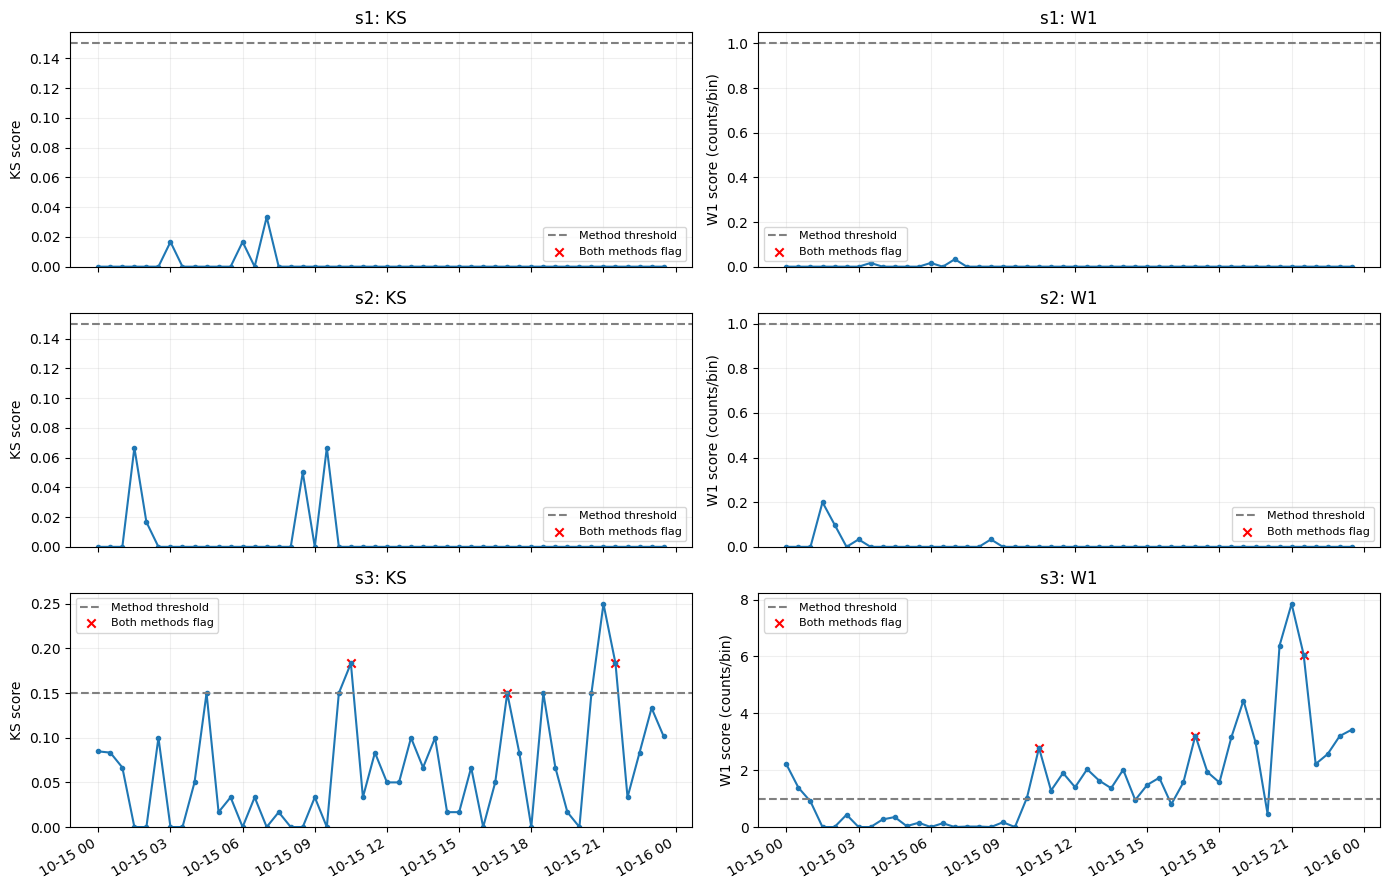

,window_start,window_end,sensor,common_bins,ks_score,ks_reference,ks_flag,w1_score,w1_reference,w1_flag,anomaly,status
65,2026-10-15 10:30:00,2026-10-15 11:00:00,s3,60,0.183,0.117,True,2.783,0.833,True,True,evaluated
104,2026-10-15 17:00:00,2026-10-15 17:30:00,s3,60,0.150,0.083,True,3.217,0.667,True,True,evaluated
131,2026-10-15 21:30:00,2026-10-15 22:00:00,s3,60,0.183,0.100,True,6.067,0.933,True,True,evaluated


In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for row, sensor in enumerate(sensors):
    data = results[results["sensor"] == sensor]
    flagged = data[data["anomaly"]]
    for col, (method, threshold) in enumerate([("ks", KS_THRESHOLD), ("w1", W1_THRESHOLD)]):
        ax = axes[row, col]
        ax.plot(data["window_start"], data[f"{method}_score"], marker=".")
        ax.axhline(threshold, color="gray", linestyle="--", label="Method threshold")
        ax.scatter(flagged["window_start"], flagged[f"{method}_score"], color="red", marker="x", label="Both methods flag")
        ax.set_title(f"{sensor}: {method.upper()}")
        ax.set_ylabel("KS score" if method == "ks" else "W1 score (counts/bin)")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
display(results[results["anomaly"]].round(3))

## Inspect the ECDFs for one window
Change `inspect_time` to inspect another half-hour. The title lists the combined flags. The distances above use these same count distributions.

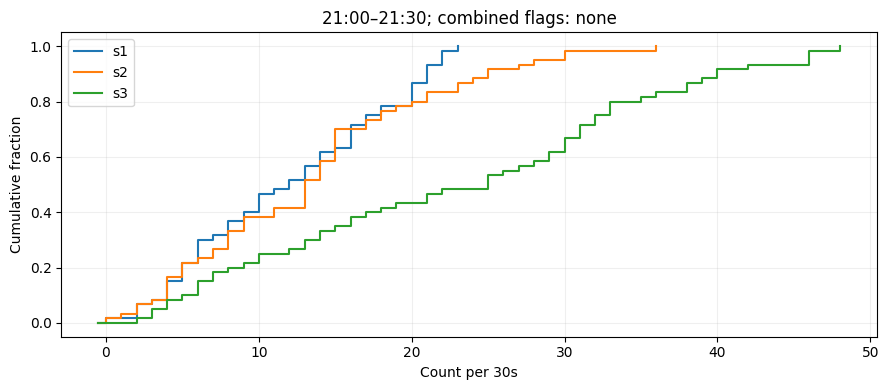

In [7]:
inspect_time = "21:00"
window_start = pd.Timestamp(f"{DAY} {inspect_time}").floor(WINDOW)
window_end = window_start + pd.Timedelta(WINDOW)
common = aligned.loc[(aligned.index >= window_start) & (aligned.index < window_end)].dropna()
if common.empty:
    print("No common coverage for this window.")
else:
    fig, ax = plt.subplots(figsize=(9, 4))
    for sensor in sensors:
        values = np.sort(common[sensor].to_numpy())
        x = np.unique(values)
        y = np.searchsorted(values, x, side="right") / len(values)
        ax.step(np.r_[-0.5, x], np.r_[0, y], where="post", label=sensor)
    flags = results[(results["window_start"] == window_start) & results["anomaly"]]["sensor"].tolist()
    ax.set_title(f"{window_start:%H:%M}–{window_end:%H:%M}; combined flags: {', '.join(flags) or 'none'}")
    ax.set_xlabel(f"Count per {BIN}")
    ax.set_ylabel("Cumulative fraction")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()